In [156]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

✅ TASK 2: Unemployment Analysis Using Python

 Analyze unemployment rate data representing the percentage of unemployed individuals.

 Perform data cleaning, exploration, and visualization using Python.

 Study the impact of COVID-19 on unemployment trends.

 Identify key patterns, correlations, or seasonal trends.

 Present insights that can support economic or policy-level decision-making.


## Basic Data Understanding

In [157]:
df = pd.read_csv("/content/Unemployment in India.csv")

In [158]:
# first five rows

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [159]:
# shape

shape = df.shape
print(f" number of rows and columns in data is {shape}")

 number of rows and columns in data is (768, 7)


In [160]:
# info of data

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [161]:
# columns of data

df.columns

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

In [162]:
# to check whether null values are present or not

no_null_values = df.isnull().sum()
print(f" the total no of null values present in the data is\n {no_null_values}")

 the total no of null values present in the data is
 Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64


In [163]:
#  to check data has duplicates values or not

no_duplicates = df.duplicated().sum()
print(f" the total no of duplicate values present in data is {no_duplicates}")

 the total no of duplicate values present in data is 27


In [164]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [165]:
# check nunique

df.nunique()

,0
Region,28
Date,14
Frequency,2
Estimated Unemployment Rate (%),624
Estimated Employed,740
Estimated Labour Participation Rate (%),626
Area,2


# Data Cleaning


In [166]:
# to see where null values are in data

df[df.isnull().any(axis=1)]

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [167]:
# drop all nan values

df.dropna(how='all', inplace=True)

In [168]:
 # check the null values drop or not

df.isnull().sum()

,0
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0


In [169]:
# check duplictees remove or not >> all nan values removed

df.duplicated().sum()

np.int64(0)

In [170]:
# strip extra spaces

df.columns = df.columns.str.strip()

In [171]:
df.columns = df.columns.str.replace(" ", "_")
df.columns

Index(['Region', 'Date', 'Frequency', 'Estimated_Unemployment_Rate_(%)',
       'Estimated_Employed', 'Estimated_Labour_Participation_Rate_(%)',
       'Area'],
      dtype='object')

In [172]:
# feature engineering >> covert date col from object to date

df['Date'] = pd.to_datetime(df['Date'])

print("The data type of date column is ", df['Date'].dtype)

The data type of date column is  datetime64[ns]


In [173]:
# Range of date time column is

print(df['Date'].min())
print(df['Date'].max())

2019-05-31 00:00:00
2020-06-30 00:00:00


In [174]:
# to see unique values

df['Region'].unique()

array(['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Goa',
       'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir',
       'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh',
       'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab',
       'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura',
       'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'Chandigarh'],
      dtype=object)

In [175]:
#  to see unique values of frequency column

df['Frequency'].unique()

array([' Monthly', 'Monthly'], dtype=object)

In [176]:
# remove extra space present in ' Monthly'

df['Frequency'] = df['Frequency'].str.strip()


print(df['Frequency'].unique())

['Monthly']


In [177]:
#  to see unique values of area column

df['Area'].unique()

array(['Rural', 'Urban'], dtype=object)

In [178]:
# to see unique values for date

df['Date'].unique()

<DatetimeArray>
['2019-05-31 00:00:00', '2019-06-30 00:00:00', '2019-07-31 00:00:00',
 '2019-08-31 00:00:00', '2019-09-30 00:00:00', '2019-10-31 00:00:00',
 '2019-11-30 00:00:00', '2019-12-31 00:00:00', '2020-01-31 00:00:00',
 '2020-02-29 00:00:00', '2020-03-31 00:00:00', '2020-04-30 00:00:00',
 '2020-05-31 00:00:00', '2020-06-30 00:00:00']
Length: 14, dtype: datetime64[ns]

## EDA

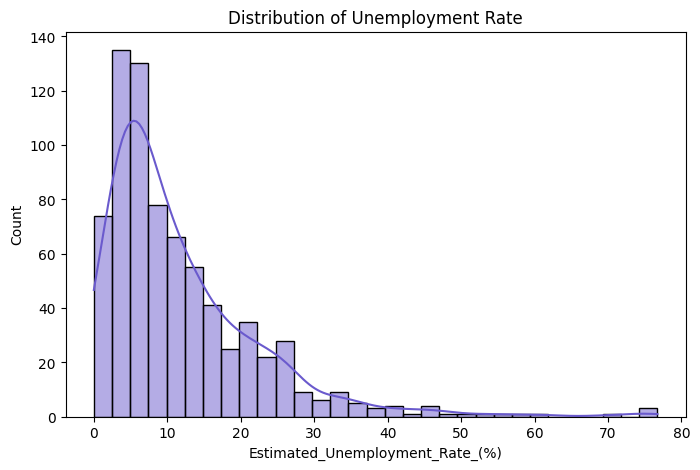

In [179]:
# Unemployment rate distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Estimated_Unemployment_Rate_(%)', kde=True, color = 'slateblue')
plt.title('Distribution of Unemployment Rate')
plt.show()

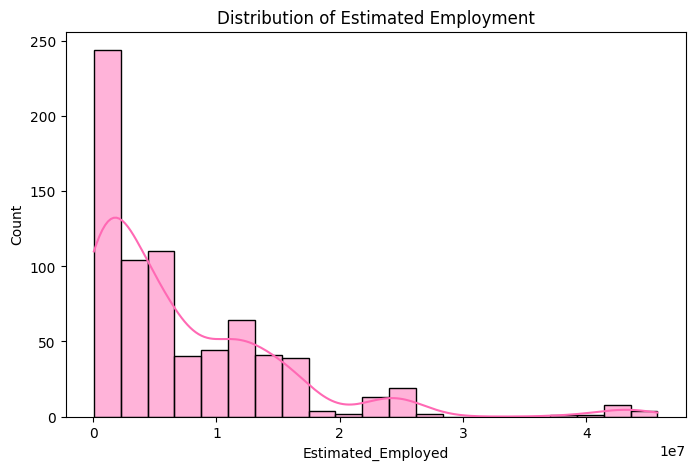

In [180]:
#  Estimated Employement distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Estimated_Employed', kde=True, color = 'hotpink')
plt.title('Distribution of Estimated Employment')
plt.show()

Text(0.5, 1.0, 'Correlation Heatmap')

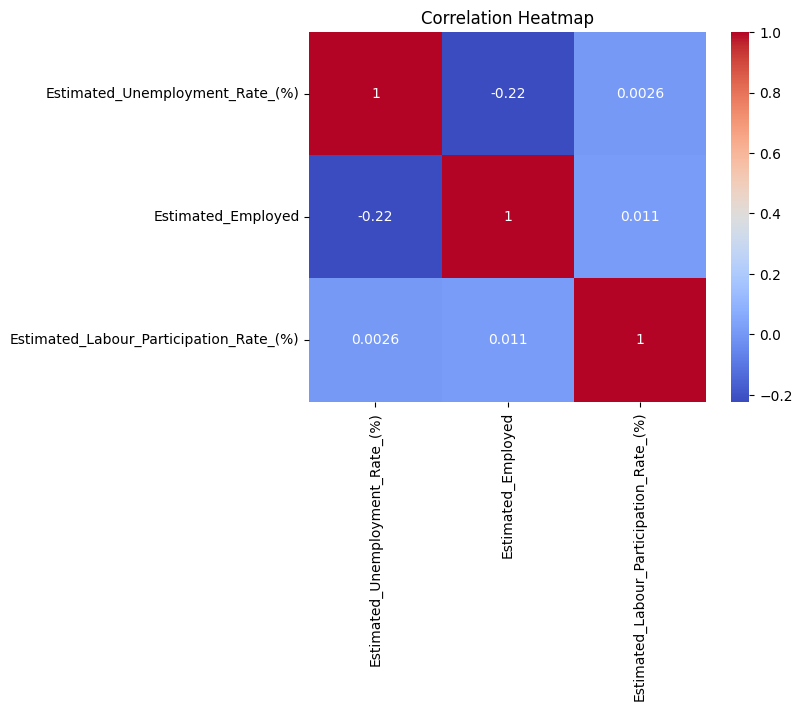

In [181]:
# Heatmap for correlation

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

<Figure size 1400x1000 with 0 Axes>

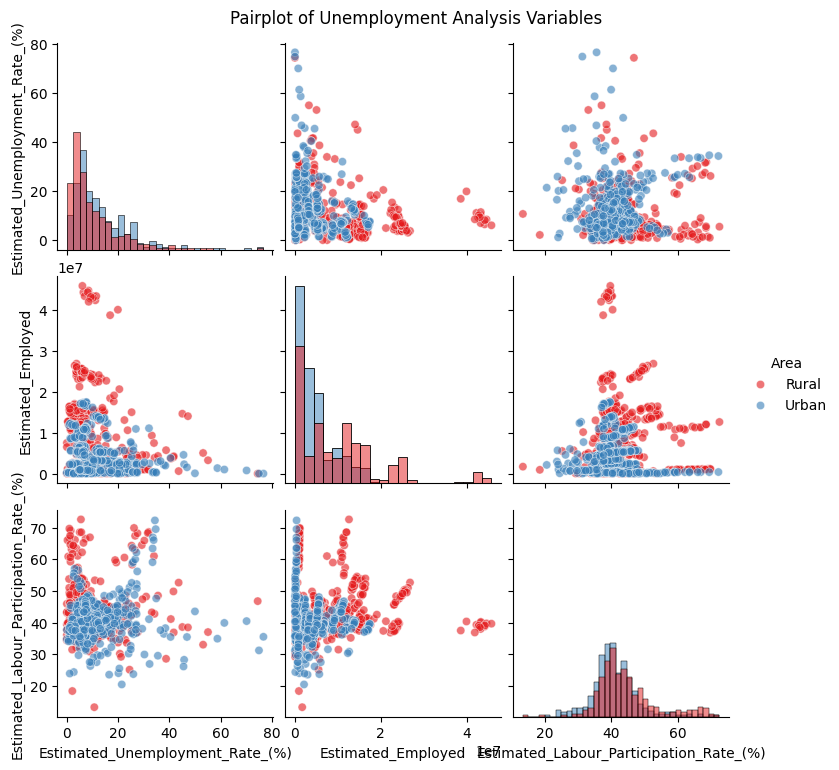

In [182]:
# Pair plot

plt.figure(figsize=(14, 10))
sns.pairplot(
    df[
        ["Estimated_Unemployment_Rate_(%)","Estimated_Employed","Estimated_Labour_Participation_Rate_(%)","Area"]
    ],
    hue="Area",
    diag_kind="hist",
    palette="Set1",
    plot_kws={"alpha": 0.6}
)

plt.suptitle("Pairplot of Unemployment Analysis Variables", y=1.02)
plt.show()

In [183]:
# Regional Unemployment Rate Analysis

region_unemployment = df.groupby('Region')[
    'Estimated_Unemployment_Rate_(%)'
].mean().sort_values(ascending=False)

print(region_unemployment)

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated_Unemployment_Rate_(%), dtype: float64


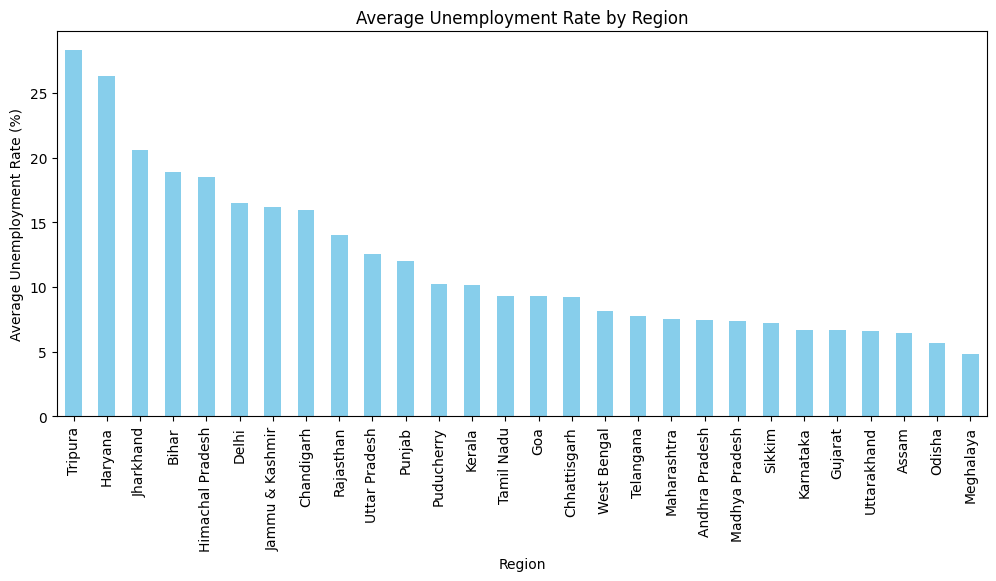

In [184]:
# unemployment by region

region_unemployment.plot(kind='bar', figsize=(12, 5), color = 'skyblue')
plt.title('Average Unemployment Rate by Region')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.show()

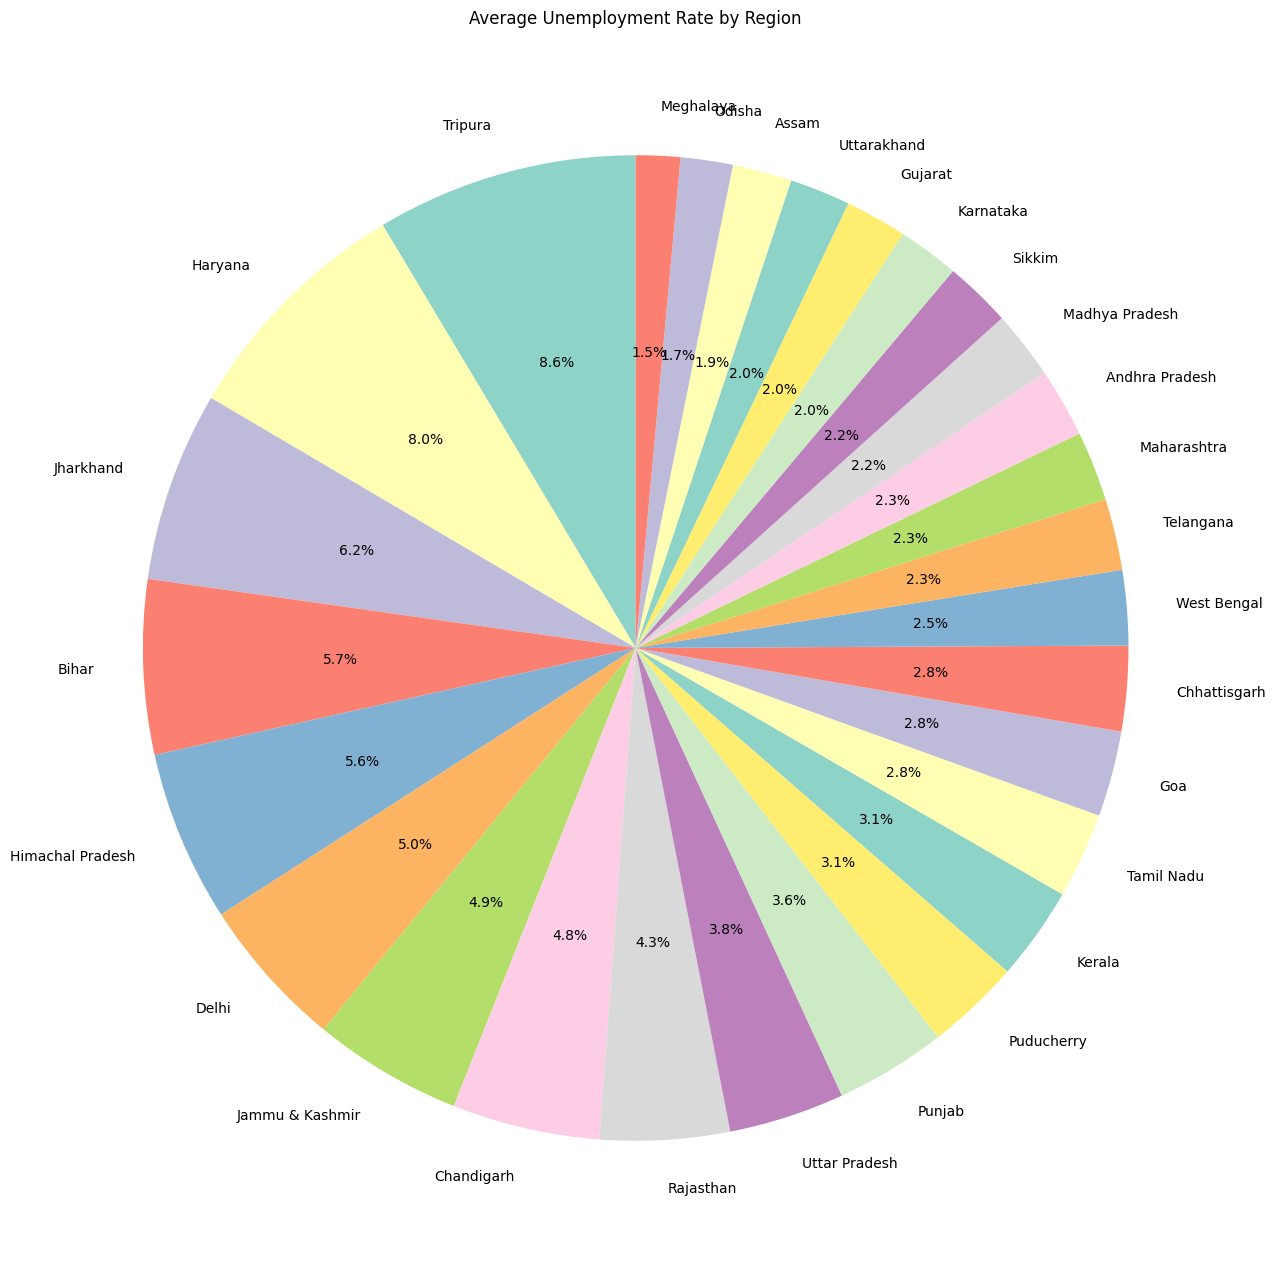

In [185]:
#  pie chart of Region

plt.figure(figsize=(16, 16))

plt.pie(
    region_unemployment,
    labels=region_unemployment.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=plt.cm.Set3.colors
)

plt.title('Average Unemployment Rate by Region')
plt.show()

In [186]:
# Top 5 regions with highest unemployment

print("Top 5 regions with highest unemployment:")
print(region_unemployment.head(5))

Top 5 regions with highest unemployment:
Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Name: Estimated_Unemployment_Rate_(%), dtype: float64


In [187]:
# Top 5 regions with lowest unemployment

print("Top 5 regions with lowest unemployment:")
print(region_unemployment.tail(5).sort_values())

Top 5 regions with lowest unemployment:
Region
Meghalaya      4.798889
Odisha         5.657857
Assam          6.428077
Uttarakhand    6.582963
Gujarat        6.663929
Name: Estimated_Unemployment_Rate_(%), dtype: float64


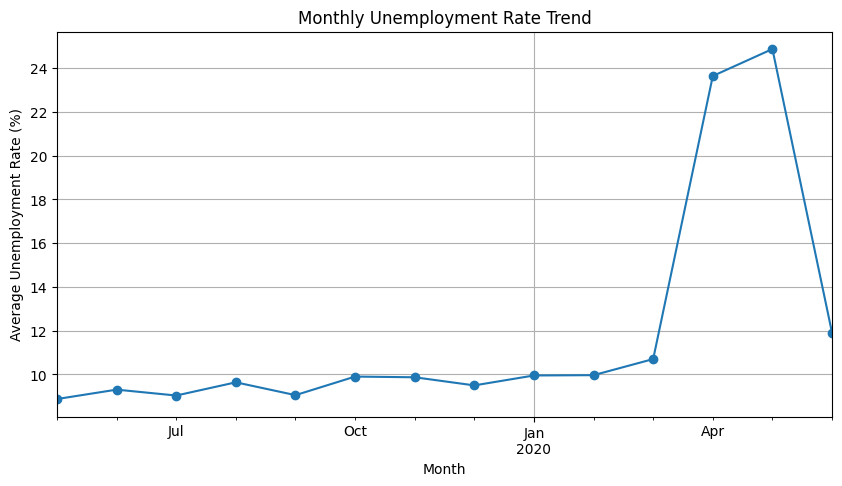

In [188]:
# Analyze trends over time

monthly = df.groupby(df['Date'].dt.to_period('M'))[
    'Estimated_Unemployment_Rate_(%)'
].mean()

monthly.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Monthly Unemployment Rate Trend')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.grid(True)
plt.show()

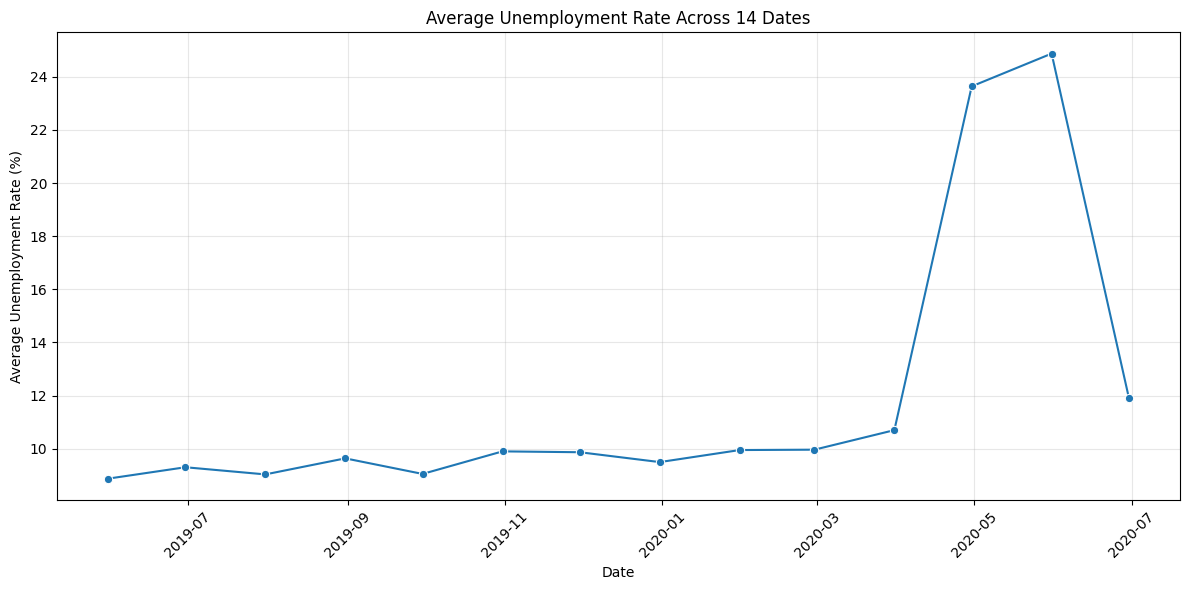

In [198]:
# Plot unemployment trends across the dates

date_trend = df.groupby('Date')['Estimated_Unemployment_Rate_(%)'].mean()

plt.figure(figsize=(12, 6))
sns.lineplot(x=date_trend.index, y=date_trend.values, marker='o')

plt.title('Average Unemployment Rate Across 14 Dates')
plt.xlabel('Date')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

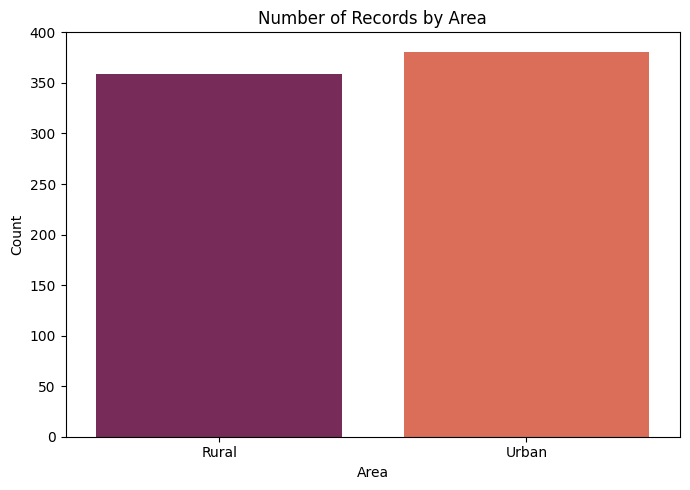

In [189]:
# count plot of area

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Area', hue='Area', legend=False, palette = 'rocket')

plt.title('Number of Records by Area')
plt.xlabel('Area')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

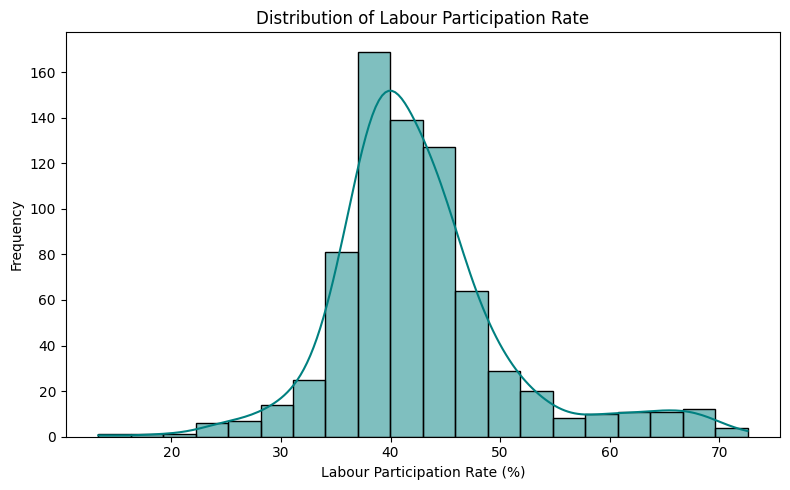

In [190]:
# Distribution of Labour Participation Rate.”

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Estimated_Labour_Participation_Rate_(%)',
    bins=20,
    kde=True,
    color='teal'
)

plt.title('Distribution of Labour Participation Rate')
plt.xlabel('Labour Participation Rate (%)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

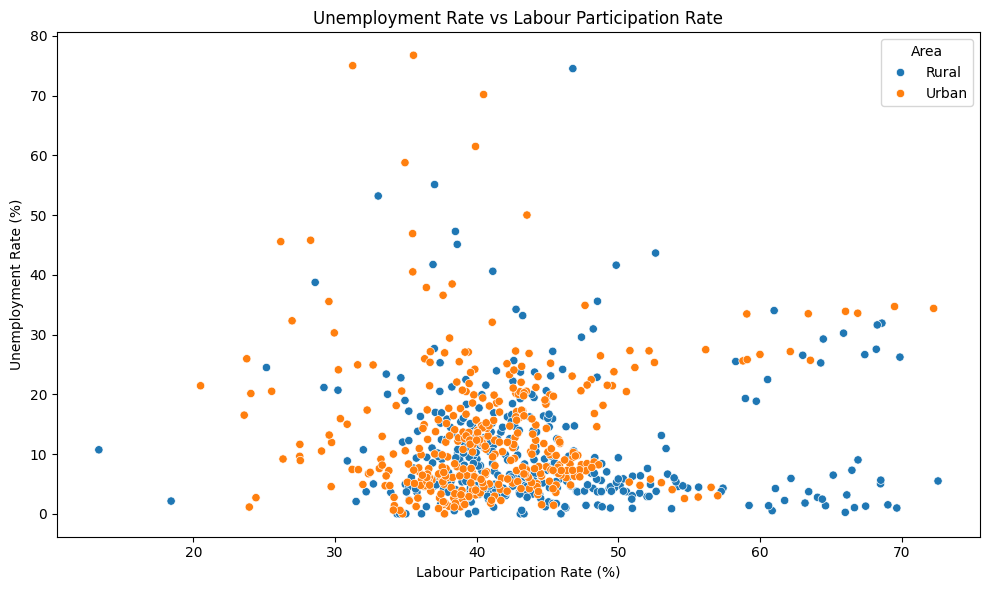

In [191]:
# Scatter plot between Unemployment Rate vs Labour Participation Rate

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Estimated_Labour_Participation_Rate_(%)',
    y='Estimated_Unemployment_Rate_(%)',
    hue='Area'
)

plt.title('Unemployment Rate vs Labour Participation Rate')
plt.xlabel('Labour Participation Rate (%)')
plt.ylabel('Unemployment Rate (%)')
plt.tight_layout()
plt.show()

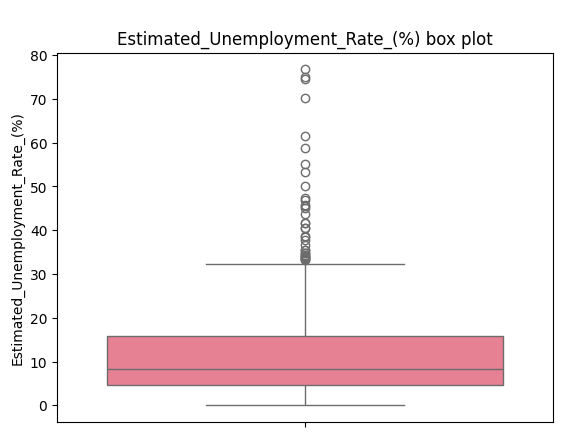

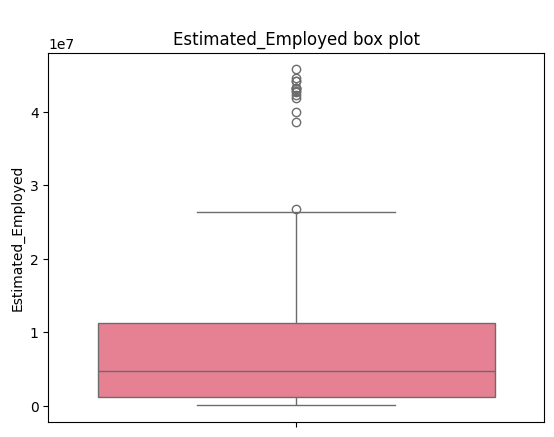

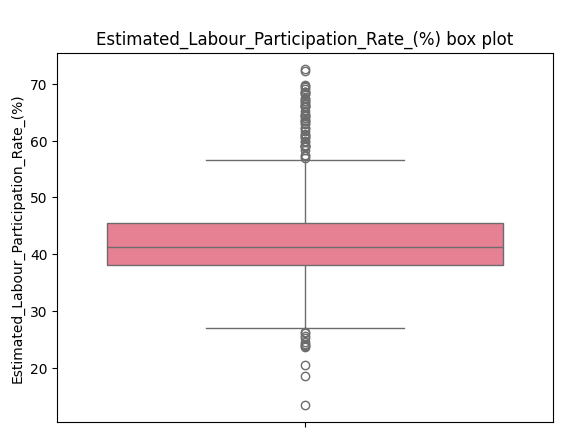

In [192]:
# box plot for Estimated unemployment rate

columns = [
    'Estimated_Unemployment_Rate_(%)',
    'Estimated_Employed',
    'Estimated_Labour_Participation_Rate_(%)'
]

for col in columns :
  sns.boxplot(y=df[col], palette='husl')
  plt.title(f'\n{col} box plot')
  plt.show()

In [193]:
# Outliers for Estimated_Unemployment_Rate_(%)

col = 'Estimated_Unemployment_Rate_(%)'

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df[col] < lower) |
    (df[col] > upper)
]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

outliers[[col, 'Region', 'Date', 'Area']]


Lower limit: -12.187499999999998
Upper limit: 32.7325
Number of outliers: 35


,Estimated_Unemployment_Rate_(%),Region,Date,Area
37,45.09,Bihar,2020-04-30,Rural
38,47.26,Bihar,2020-05-31,Rural
105,41.61,Haryana,2020-04-30,Rural
106,34.22,Haryana,2020-05-31,Rural
107,35.57,Haryana,2020-06-30,Rural
144,41.72,Jharkhand,2020-04-30,Rural
145,55.10,Jharkhand,2020-05-31,Rural
158,33.17,Karnataka,2020-04-30,Rural
242,74.51,Puducherry,2020-04-30,Rural
255,40.59,Punjab,2020-05-31,Rural


In [194]:
# Outliers for 'Estimated_Employed'

col = 'Estimated_Employed'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df[col] < lower) |
    (df[col] > upper)
]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

outliers[[col, 'Region', 'Date', 'Area']]


Lower limit: -13937223.0
Upper limit: 26403117.0
Number of outliers: 15


,Estimated_Employed,Region,Date,Area
192,26835389.0,Maharashtra,2019-08-31,Rural
318,43287808.0,Uttar Pradesh,2019-05-31,Rural
319,42276572.0,Uttar Pradesh,2019-06-30,Rural
320,42697000.0,Uttar Pradesh,2019-07-31,Rural
321,43298746.0,Uttar Pradesh,2019-08-31,Rural
322,44198762.0,Uttar Pradesh,2019-09-30,Rural
323,42833265.0,Uttar Pradesh,2019-10-31,Rural
324,43261530.0,Uttar Pradesh,2019-11-30,Rural
325,44640087.0,Uttar Pradesh,2019-12-31,Rural
326,45777509.0,Uttar Pradesh,2020-01-31,Rural


In [195]:
# Outliers for Estimated_Labour_Participation_Rate_(%)

col = 'Estimated_Labour_Participation_Rate_(%)'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df[col] < lower) |
    (df[col] > upper)
]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

outliers[[col, 'Region', 'Date', 'Area']]


Lower limit: 26.898749999999996
Upper limit: 56.66875
Number of outliers: 63


,Estimated_Labour_Participation_Rate_(%),Region,Date,Area
14,57.39,Assam,2019-05-31,Rural
119,18.43,Himachal Pradesh,2020-04-30,Rural
172,13.33,Kerala,2020-04-30,Rural
203,66.13,Meghalaya,2019-05-31,Rural
204,61.09,Meghalaya,2019-06-30,Rural
...,...,...,...,...
705,63.41,Tripura,2019-12-31,Urban
706,72.26,Tripura,2020-01-31,Urban
707,66.04,Tripura,2020-02-29,Urban
708,63.56,Tripura,2020-03-31,Urban


In [196]:
# Create a COVID-19 period column

df['Period'] = df['Date'].apply(
    lambda date: 'Before COVID-19'
    if date < pd.Timestamp('2020-03-01')
    else 'During COVID-19'
)

# Calculate average unemployment rate for each period

covid_analysis = df.groupby('Period')[
    'Estimated_Unemployment_Rate_(%)'
].mean()

print(covid_analysis)

Period
Before COVID-19     9.509534
During COVID-19    17.774363
Name: Estimated_Unemployment_Rate_(%), dtype: float64


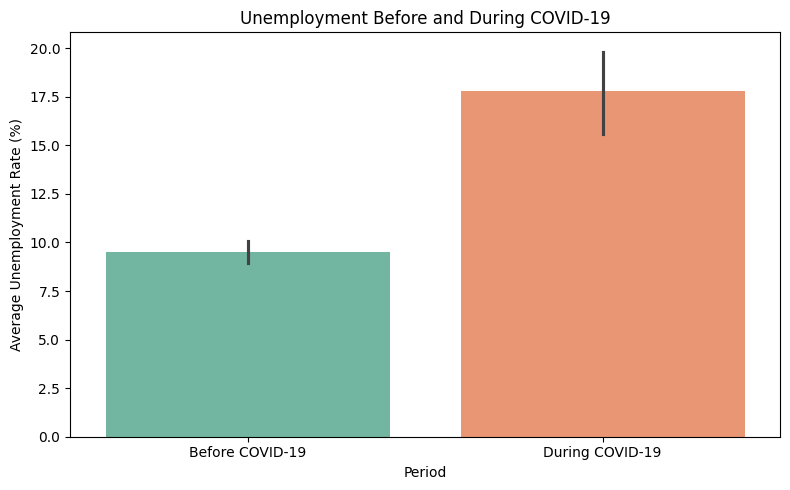

In [197]:
# Bar plot between Unemployment Before and During COVID-19

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Period',
    y='Estimated_Unemployment_Rate_(%)',
    hue='Period',
    palette='Set2'
)

plt.title('Unemployment Before and During COVID-19')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

# Findings and Insights

*  **Unemployment Rate Distribution:** The unemployment rate distribution is positively skewed. Most observations are concentrated at relatively low unemployment rates, while a smaller number of observations have much higher rates.

* **Estimated Employment Distribution:** The estimated employment values are also right-skewed. This indicates that many observations have lower employment estimates, while a smaller number have substantially higher values. These differences may reflect variations in population and economic activity across regions.

*  **Regional Unemployment Differences:** The regional comparison shows considerable variation in average unemployment rates. Tripura has the highest average unemployment rate, while Meghalaya has the lowest among the regions shown in the analysis. This highlights the importance of region-specific employment policies.

* **Monthly Unemployment Trend:** The monthly trend shows relatively stable average unemployment rates before March 2020, followed by a sharp increase in April and May 2020. The average rate then declined in June 2020. This pattern coincides with the initial COVID-19 disruption and lockdown period.

* **Urban and Rural Observations:** The dataset contains observations from both urban and rural areas, with the number of records being relatively similar.

*  **Labour Force Participation:** The labour participation rate is concentrated mainly around the mid-30% to mid-40% range, with some observations at higher values. Understanding these differences can help policymakers investigate variations in workforce participation across regions.

* **Relationship Between Unemployment and Labour Participation:** The scatterplot shows considerable variation in unemployment rates at different labour participation levels. The relationship should be evaluated using a correlation coefficient before concluding whether it is positive, negative, or weak.

* **Impact of COVID-19:** The average unemployment rate increased from approximately 9.51% before March 2020 to 17.78% from March 2020 onward. This represents an increase of approximately 8.27 percentage points. The comparison suggests a substantial rise during the period examined,

# Conclusion

This project analyzed unemployment patterns using Python, Pandas, Matplotlib, and Seaborn. Data cleaning, exploratory data analysis, and visualization helped identify differences in unemployment distributions, regional averages, monthly trends, and labour force participation.

The sharp rise in unemployment observed around April and May 2020 highlights the vulnerability of employment to major economic disruptions. Regional differences also suggest that a uniform employment strategy may not address the needs of every region equally.

Based on these findings, policymakers could strengthen employment support during economic crises, encourage small-business development, expand vocational training, and design targeted employment programs for regions with persistently high unemployment. Regular monitoring of unemployment and labour force participation can help evaluate the effectiveness of these measures.

Overall, this analysis demonstrates how data-driven insights can support employment planning and economic decision-making. Further analysis using additional economic indicators and data from a longer period would help distinguish temporary changes from persistent trends.


# Insights that can support economic or policy-level decision-making

## Conclusion and Policy Recommendations

The unemployment analysis highlights important differences in unemployment across time and regions. The average unemployment rate increased from approximately 9.51% before March 2020 to 17.78% from March 2020 onward, indicating a substantial rise during the period examined. Regional comparisons also showed differences in average unemployment, with Tripura recording the highest and Meghalaya the lowest average rates in this dataset.

These findings suggest that policymakers should strengthen employment support during economic disruptions, encourage local business development, invest in skill-based training, and design employment programs suited to regional needs. Monthly trends and labour force participation should also be monitored to identify recurring patterns and barriers to employment.

